<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Student Performance Segmentation and Academic Success Profiling</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Structural Verification (4 Marks)

Load the StudentsPerformance.csv dataset from the verified URL: https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv. Read it into a pandas DataFrame named df. Verify the data ingestion by asserting that the DataFrame contains exactly 1000 rows and 8 columns. Display the deep memory usage and the first 3 rows of the dataset.

Hint: Use pd.read_csv() to load the data. You can verify the dimensions using the .shape attribute and display detailed memory usage with df.info(memory_usage='deep').

Expected Output: A summary of the DataFrame's memory allocation and a tabular preview displaying the first three records of the dataset.

In [18]:
# Write your answer here
import pandas as pd
df=pd.read_csv("https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv")
assert df.shape == (1000, 8), "Unexpected shape"
df.info(memory_usage='deep')
df.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 303.7 KB


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93


### Question 2: Data Standardization and Missing Value Strategy (5 Marks)

The dataset columns contain spaces and special characters. Rename the columns by replacing all spaces and slashes with underscores (e.g., 'math score' becomes 'math_score', 'race/ethnicity' becomes 'race_ethnicity'). Drop any duplicate rows. Print the sum of missing values for each column to verify data integrity. Finally, print a 1-2 sentence justification on why verifying and handling missing values early is critical for distance-based machine learning algorithms.

Hint: Use the df.rename() method with a lambda function or list comprehension. Check for nulls using df.isnull().sum(). Use print() for your written justification.

Expected Output: A printed series showing zero missing values for the standardized column names, followed by a printed analytical statement explaining the mathematical sensitivity of algorithms to null values.

In [19]:
# Write your answer here
df = df.rename(columns=lambda x: x.replace(' ', '_').replace('/', '_'))
df=df.drop_duplicates()
print(df.isnull().sum())
print("\n Verifying and handling missing values early is critical for distance-based machine learning algorithms (such as K-Nearest Neighbors, K-Means Clustering) because these models rely directly on mathematical distance metrics to compute similarities between data points.")

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

 Verifying and handling missing values early is critical for distance-based machine learning algorithms (such as K-Nearest Neighbors, K-Means Clustering) because these models rely directly on mathematical distance metrics to compute similarities between data points.


### Question 3: Exploratory Data Analysis: Correlation Matrices (8 Marks)

Perform Exploratory Data Analysis (EDA) by calculating the Pearson correlation matrix for the numerical features (math_score, reading_score, writing_score). Visualize this matrix using a seaborn heatmap with annotations enabled. Print a written analysis identifying which two subjects exhibit the strongest correlation and hypothesize a brief academic reason why.

Hint: Isolate the numerical columns and use the .corr() method. Pass the resulting matrix to sns.heatmap(annot=True). Use print() to output your textual analysis.

Expected Output: A heatmap plot displaying a color gradient representative of correlation strength between the subjects, accompanied by a printed analytical conclusion.

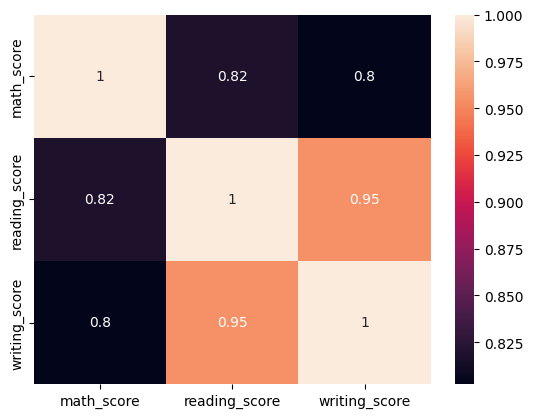

In [20]:
# Write your answer here
import seaborn as sns
import matplotlib.pyplot as plt
df_num = df[['math_score', 'reading_score', 'writing_score']]
corr_matrix = df_num.corr()
sns.heatmap(corr_matrix, annot=True)
plt.show()

In [21]:
print("Reading and writing are strongly correlated (0.95), this was expected as both reading and writing test the linguistic ability, thus the high association")

Reading and writing are strongly correlated (0.95), this was expected as both reading and writing test the linguistic ability, thus the high association


### Question 4: Feature Engineering: Composite Performance (6 Marks)

Calculate an overall academic performance metric for the students rather than relying on isolated subject scores. Create a new numerical column named composite_score that represents the mean of math_score, reading_score, and writing_score for each row. Drop the three original subject score columns from the DataFrame.

Hint: Compute the mean across the horizontal axis (axis=1) for the specific score columns. Use df.drop(columns=[...]) to remove the redundant features.

Expected Output: A modified pandas DataFrame reflecting the updated schema where the three individual score columns are replaced by a single composite metric.

In [22]:
# Write your answer here
df['composite_score'] = df[['math_score', 'reading_score', 'writing_score']].mean(axis=1)
df = df.drop(columns=['math_score', 'reading_score', 'writing_score'])
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,composite_score
0,female,group B,bachelor's degree,standard,none,72.666667
1,female,group C,some college,standard,completed,82.333333
2,female,group B,master's degree,standard,none,92.666667
3,male,group A,associate's degree,free/reduced,none,49.333333
4,male,group C,some college,standard,none,76.333333


### Question 5: Categorical Encoding (6 Marks)

Convert the categorical variables (gender, race_ethnicity, parental_level_of_education, lunch, and test_preparation_course) into numerical format using one-hot encoding. Set drop_first=True to mitigate multicollinearity. Save this numerical dataset as a new DataFrame named df_encoded.

Hint: Utilize the pd.get_dummies() function on the categorical columns. Ensure boolean outputs are cast to integers (0s and 1s).

Expected Output: A widened DataFrame where the original text-based categorical columns are replaced by binary numerical indicators alongside the continuous composite_score.

In [23]:
# Write your answer here
df_encoded = pd.get_dummies(df, drop_first= True, dtype=int)
df_encoded.head()

,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,72.666667,0,1,0,0,0,1,0,0,0,0,1,1
1,82.333333,0,0,1,0,0,0,0,0,1,0,1,0
2,92.666667,0,1,0,0,0,0,0,1,0,0,1,1
3,49.333333,1,0,0,0,0,0,0,0,0,0,0,1
4,76.333333,1,0,1,0,0,0,0,0,1,0,1,1


### Question 6: Feature Scaling and Dimensional Retention (6 Marks)

Distance-based algorithms require scaled features to prevent magnitude bias. Standardize all features in df_encoded so that they have a mean of 0 and a standard deviation of 1. Explicitly convert the resulting scaled NumPy array back into a pandas DataFrame named X_scaled, retaining the exact column names from df_encoded.

Hint: Apply the fit_transform method from sklearn's StandardScaler. Wrap the output using pd.DataFrame(), explicitly assigning the columns parameter to df_encoded.columns.

Expected Output: A standardized pandas DataFrame consisting entirely of scaled numerical values, with the original feature headers fully intact.

In [24]:
# Write your answer here
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_encoded)
X_scaled = pd.DataFrame(X_scaled, columns=df_encoded.columns)
X_scaled.head()

,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,0.343574,-0.964625,2.064742,-0.684419,-0.59583,-0.403473,2.733967,-0.493742,-0.250398,-0.540361,-0.466933,0.741881,0.746748
1,1.021927,-0.964625,-0.484322,1.461094,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,0.741881,-1.339140
2,1.747064,-0.964625,2.064742,-0.684419,-0.59583,-0.403473,-0.365769,-0.493742,3.993639,-0.540361,-0.466933,0.741881,0.746748
3,-1.293830,1.036672,-0.484322,-0.684419,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,-0.540361,-0.466933,-1.347925,0.746748
4,0.600881,1.036672,-0.484322,1.461094,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,0.741881,0.746748


### Question 7: Cluster Optimization via Elbow Method (7 Marks)

Determine the optimal number of segments (k) for K-Means using the Elbow Method. Iterate k from 1 to 10. For each k, fit a KMeans model on X_scaled (setting random_state=42) and record the model's inertia. Plot these inertia values against the number of clusters using matplotlib.

Hint: Initialize an empty list. In a for loop, instantiate KMeans, fit the model to X_scaled, and append the .inertia_ attribute. Plot the resulting list as a line chart.

Expected Output: A line chart revealing a decreasing curve, allowing visual identification of the inflection point (elbow) for optimal cluster selection.

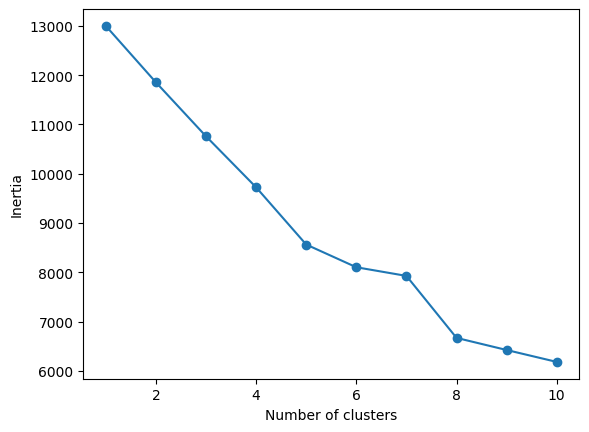

In [25]:
# Write your answer here
from sklearn.cluster import KMeans
res_list= []
for k in range(1,11):
  kmeans = KMeans(n_clusters=k, random_state=42)
  kmeans.fit(X_scaled)
  res_list.append(kmeans.inertia_)
plt.plot(range(1,11), res_list, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

### Question 8: K-Means Implementation and Silhouette Validation (7 Marks)

Assume the optimal number of clusters is 4. Instantiate a KMeans model with n_clusters=4 and random_state=42. Fit the model on X_scaled and extract the cluster assignments. Append these assignments as a new column named cluster_label in the original, unscaled df_encoded DataFrame. Calculate and print the Silhouette Score to mathematically validate the cluster cohesion.

Hint: Extract assignments using the .labels_ attribute. Import silhouette_score from sklearn.metrics, passing X_scaled and the predicted labels to compute the metric.

Expected Output: The unscaled DataFrame updated with integer cluster assignments, and a printed floating-point metric quantifying the density and separation of the segments.

In [26]:
# Write your answer here
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
kmeans=KMeans(n_clusters=4, random_state=42)
kmeans.fit(X_scaled)
df_encoded['cluster_label'] = kmeans.labels_
print(silhouette_score(X_scaled, kmeans.labels_))
df_encoded.head()

0.17310504224398726


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none,cluster_label
0,72.666667,0,1,0,0,0,1,0,0,0,0,1,1,0
1,82.333333,0,0,1,0,0,0,0,0,1,0,1,0,2
2,92.666667,0,1,0,0,0,0,0,1,0,0,1,1,1
3,49.333333,1,0,0,0,0,0,0,0,0,0,0,1,2
4,76.333333,1,0,1,0,0,0,0,0,1,0,1,1,2


### Question 9: Cluster Profiling and Interpretation (8 Marks)

Analyze the defining characteristics of each cluster. Group the df_encoded DataFrame by the cluster_label column and calculate the mean for all features. Display the aggregated table. Below the table, print a written analysis detailing the specific demographic and preparation traits that distinguish the cluster with the highest average composite score.

Hint: Utilize .groupby('cluster_label').mean(). Observe the binary categorical flags in the row corresponding to the highest composite_score to formulate your written response.

Expected Output: A statistical summary table with 4 rows representing the cluster centroids, followed by a printed conceptual assessment of the highest-performing student segment.

In [27]:
# Write your answer here
cluster_means = df_encoded.groupby('cluster_label').mean()
display(cluster_means)

# Identifying the cluster with the highest average composite score
best_cluster = cluster_means['composite_score'].idxmax() #using function idxmax to get the max index in composite_score
print("Cluster ", best_cluster, " has the highest average composite score.")
print("\n We notice an exclusive representation from race_ethnicity of group E.")
print("\n A higher proportion of students who completed test preparation (0.43 vs 0.36 overall).")
print("\n A higher proportion of students with standard lunch (0.71 vs 0.64 overall).")

,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
cluster_label,,,,,,,,,,,,,
0,71.263333,0.470000,0.2,0.400000,0.28000,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.600000,0.640000
1,64.782353,0.452941,1.0,0.000000,0.00000,0.0,0.000000,0.282353,0.035294,0.217647,0.223529,0.647059,0.617647
2,66.857627,0.486441,0.0,0.472881,0.39661,0.0,0.000000,0.213559,0.076271,0.261017,0.208475,0.637288,0.666102
3,72.752381,0.507143,0.0,0.000000,0.00000,1.0,0.128571,0.157143,0.057143,0.250000,0.128571,0.707143,0.571429


Cluster  3  has the highest average composite score.

 We notice an exclusive representation from race_ethnicity of group E.

 A higher proportion of students who completed test preparation (0.43 vs 0.36 overall).

 A higher proportion of students with standard lunch (0.71 vs 0.64 overall).


### Question 10: Target Formulation and Class Imbalance Assessment (6 Marks)

Formulate a supervised learning task to predict a student's cluster segment based purely on their demographic and preparation variables. Define y as the cluster_label. Define your feature matrix X by dropping both composite_score and cluster_label from the X_scaled DataFrame to prevent data leakage. Check the class distribution of y. Print a brief analysis discussing whether class imbalance exists and how it might impact evaluation metrics.

Hint: Use .value_counts() on y. Consider whether accuracy remains a reliable metric when the distribution of classes is uneven.

Expected Output: A frequency count of the target classes and a printed analytical reasoning paragraph regarding class imbalance.

In [28]:
# Write your answer here
y = df_encoded['cluster_label']
X = X_scaled.drop(columns=['composite_score','cluster_label'], errors='ignore')

class_counts = y.value_counts()
print("Class Distribution of y is: ")
print(class_counts)

print("\nAnalysis of Class Imbalance:")
print("Moderate class imbalance exists. Cluster 2 holds 590 of 1000 students (59%), \n"
      "while Cluster 0 holds only 100 (10%), a ratio of nearly 6:1. This affects evaluation \n"
      "because accuracy can be misleading: a model that always predicts Cluster 2 would \n"
      "score 59% accuracy without learning anything about the other three segments. \n"
      "Accuracy is therefore dominated by the majority class and can hide poor performance \n"
      "on smaller clusters like Cluster 0.")

Class Distribution of y is: 
cluster_label
2    590
1    170
3    140
0    100
Name: count, dtype: int64

Analysis of Class Imbalance:
Moderate class imbalance exists. Cluster 2 holds 590 of 1000 students (59%), 
while Cluster 0 holds only 100 (10%), a ratio of nearly 6:1. This affects evaluation 
because accuracy can be misleading: a model that always predicts Cluster 2 would 
score 59% accuracy without learning anything about the other three segments. 
Accuracy is therefore dominated by the majority class and can hide poor performance 
on smaller clusters like Cluster 0.


### Question 11: Baseline Classification and Cross-Validation (8 Marks)

Split X and y into 80% training and 20% testing sets, stratifying by y to maintain class distribution. Establish a baseline by training a Logistic Regression model on the training set. Evaluate the baseline model's robustness by performing 5-fold cross-validation on the training data. Print the mean cross-validation accuracy.

Hint: Import train_test_split, LogisticRegression, and cross_val_score. Compute the mean of the array returned by the cross-validation function.

Expected Output: A printed floating-point value representing the average cross-validated accuracy of the baseline model.

In [29]:
# Write your answer here
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
baseline_model = LogisticRegression()
baseline_model.fit(X_train, y_train)
cv_scores = cross_val_score(baseline_model, X_train, y_train, cv=5)
print("Average cross-validated accuracy is: ", cv_scores.mean())
print("\nNote: The 1.0 accuracy is expected, not a sign of a good model. The clusters were \n"
      "created by K-Means on the same one-hot demographic features now used as X, so \n"
      "cluster_label is almost a deterministic function of X (e.g. group B -> cluster 1, \n"
      "group E -> cluster 3, bachelor's-degree parents -> cluster 0). The classifier is \n"
      "recovering the K-Means rule, not generalising, so this accuracy overstates real \n"
      "predictive power.")

Average cross-validated accuracy is:  1.0

Note: The 1.0 accuracy is expected, not a sign of a good model. The clusters were 
created by K-Means on the same one-hot demographic features now used as X, so 
cluster_label is almost a deterministic function of X (e.g. group B -> cluster 1, 
group E -> cluster 3, bachelor's-degree parents -> cluster 0). The classifier is 
recovering the K-Means rule, not generalising, so this accuracy overstates real 
predictive power.


### Question 12: Hyperparameter Tuning via GridSearchCV (9 Marks)

Implement Hyperparameter Tuning to optimize a RandomForestClassifier. Use GridSearchCV with a 3-fold cross-validation strategy. Define a parameter grid varying n_estimators (e.g., [50, 100, 200]) and max_depth (e.g., [None, 5, 10]). Fit the grid search on the training data and print the best hyperparameter configuration found.

Hint: Pass the model, parameter dictionary, and cv=3 to GridSearchCV. Extract the optimal configuration using the .best_params_ attribute after fitting.

Expected Output: A printed dictionary displaying the optimal hyperparameter values discovered during the exhaustive search.

In [30]:
# Write your answer here
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
par_grid={
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5,10]
}
grid_search = GridSearchCV(RandomForestClassifier(), par_grid, cv=3)
grid_search.fit(X_train, y_train)
print("Optimal hyperparameters: ", grid_search.best_params_)

Optimal hyperparameters:  {'max_depth': None, 'n_estimators': 50}


### Question 13: Multi-Layer Perceptron (MLP) Classifier (8 Marks)

Define and train a deep learning architecture using scikit-learn. Instantiate an MLPClassifier with a single hidden layer of 32 units, ReLU activation, a maximum of 500 iterations, and random_state=42. Train the model on the training data.

Hint: Import MLPClassifier from sklearn.neural_network. Set hidden_layer_sizes=(32,). Use the .fit() method on your training sets.

Expected Output: A successfully initialized and trained MLP architecture, natively handling the multi-class prediction task.

In [31]:
# Write your answer here
from sklearn.neural_network import MLPClassifier
mlp_classifier = MLPClassifier(hidden_layer_sizes=(32,), activation= 'relu', max_iter = 500, random_state=42)
mlp_classifier.fit(X_train, y_train)

MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=42)

### Question 14: Comparative Model Evaluation (6 Marks)

Comprehensively evaluate all three trained models (Baseline Logistic Regression, Tuned Random Forest, and MLP Classifier) on the unseen testing set (X_test, y_test). Calculate and print the test accuracy for each model. Print a brief analytical comparison stating which algorithm generalized best and why you suspect it outperformed the others.

Hint: Generate test predictions using .predict() for each model. Import accuracy_score from sklearn.metrics. Use print() statements for the numerical results and your comparative reasoning.

Expected Output: Three printed accuracy scores followed by a short textual assessment of the comparative algorithm performance.

In [32]:
# Write your answer here
from sklearn.metrics import accuracy_score
baseline_acc = accuracy_score(y_test, baseline_model.predict(X_test))
tuned_acc=accuracy_score(y_test, grid_search.best_estimator_.predict(X_test))
mlp_acc= accuracy_score(y_test, mlp_classifier.predict(X_test))
print("Baseline Logistic Regression Accuracy is: ", baseline_acc)
print("Tuned Random forest accuracy is: ", tuned_acc)
print("MLP classifier accuracy is: ", mlp_acc)
print("\nAnalysis: All three models score 1.0 on the test set, so none generalized \n"
      "better than the others. This is because cluster_label was produced by K-Means on \n"
      "the same one-hot features used as X, so it is an almost deterministic function of \n"
      "X. Even the simple, linear baseline can learn this rule, so the tuned Random Forest \n"
      "and MLP add nothing. The perfect scores show the models recover the clustering \n"
      "structure, not that they would predict real academic performance.")

Baseline Logistic Regression Accuracy is:  1.0
Tuned Random forest accuracy is:  1.0
MLP classifier accuracy is:  1.0

Analysis: All three models score 1.0 on the test set, so none generalized 
better than the others. This is because cluster_label was produced by K-Means on 
the same one-hot features used as X, so it is an almost deterministic function of 
X. Even the simple, linear baseline can learn this rule, so the tuned Random Forest 
and MLP add nothing. The perfect scores show the models recover the clustering 
structure, not that they would predict real academic performance.


### Question 15: Analytical Reasoning and Strategic Implementation (6 Marks)

Based on your modeling pipeline, formulate a concise 3-4 sentence business strategy explaining how an EdTech platform can utilize these predictive segments for targeted interventions. Store the response in a string variable named business_strategy and print it.

Hint: Consider how predicting a student's performance segment purely from demographic data and test preparation status upon enrollment can trigger early academic support or customized curriculum recommendations.

Expected Output: A structured paragraph printed to the screen containing actionable, domain-specific recommendations for an EdTech organization.

In [34]:
# Write your answer here
business_strategy = ("At enrollment, EdTech can use a student's background and test-prep \n"
    "status to assign them to one of the four predicted segments. Students in lower-scoring \n"
    "segments can be given early support, such as diagnostic quizzes, tutoring and test-prep \n"
    "resources, while higher-scoring segments get advanced content. Because the segments are \n"
    "driven mostly by demographic features and not by actual performance, they should be used only as \n"
    "an initial starting point and updated with real scores over time. Interventions should \n"
    "also avoid labelling students by ethnicity or background, to prevent bias.\n")
print(business_strategy)

At enrollment, EdTech can use a student's background and test-prep 
status to assign them to one of the four predicted segments. Students in lower-scoring 
segments can be given early support, such as diagnostic quizzes, tutoring and test-prep 
resources, while higher-scoring segments get advanced content. Because the segments are 
driven mostly by demographic features and not by actual performance, they should be used only as 
an initial starting point and updated with real scores over time. Interventions should 
also avoid labelling students by ethnicity or background, to prevent bias.

